##**Task 1: Data Overview**

In [ ]:
# Load the dataset

import pandas as pd
df = pd.read_csv("ecommerce_data.csv")

In [ ]:
# Display the dataset summary

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1000 non-null   object 
 1   ProductID        1000 non-null   object 
 2   Category         1000 non-null   object 
 3   Price            980 non-null    float64
 4   Quantity         980 non-null    float64
 5   Country          1000 non-null   object 
 6   PaymentMethod    1000 non-null   object 
 7   CustomerSegment  1000 non-null   object 
 8   OrderDate        1000 non-null   object 
 9   TotalSales       1000 non-null   float64
dtypes: float64(3), object(7)
memory usage: 78.3+ KB


In [ ]:
# Display the first five rows of the dataset

df.head()

,OrderID,ProductID,Category,Price,Quantity,Country,PaymentMethod,CustomerSegment,OrderDate,TotalSales
0,O00001,P0103,Electronics,25.58,5.0,UK,Bank Transfer,Wholesale,2018-11-21,127.90
1,O00002,P0271,Beauty,78.43,5.0,Canada,PayPal,Wholesale,2017-05-15,392.15
2,O00003,P0107,Beauty,493.38,5.0,Canada,Cash on Delivery,Regular,2020-11-23,2466.90
3,O00004,P0072,Sports,482.73,5.0,India,Cash on Delivery,Wholesale,2018-01-13,2413.65
4,O00005,P0189,Home & Kitchen,7.45,3.0,Australia,Bank Transfer,Regular,2015-08-02,22.35


The dataset contains 1,000 online orders from different countries, product categories, and customer segments. Price and Quantity have 20 missing values each.

##**Task 2: Data Analysis**

In [ ]:
# Display the number of unique product categories
df["Category"].nunique()

7

In [ ]:
# Display the dimensions of the dataset

df.shape

(1000, 10)

In [ ]:
# Display the total number of transactions

len(df)

1000

In [ ]:
# Display missing values per column

df.isnull().sum()

,0
OrderID,0
ProductID,0
Category,0
Price,20
Quantity,20
Country,0
PaymentMethod,0
CustomerSegment,0
OrderDate,0
TotalSales,0


In [ ]:
# Display the number of transactions with negative TotalSales

(df["TotalSales"] < 0).sum()

np.int64(10)

In [ ]:
# Display rows with negative TotalSales

df[df["TotalSales"] < 0]

,OrderID,ProductID,Category,Price,Quantity,Country,PaymentMethod,CustomerSegment,OrderDate,TotalSales
139,O00140,P0128,Home & Kitchen,122.25,2.0,India,PayPal,Wholesale,2023-02-10,-100.0
307,O00308,P0176,Toys,309.53,8.0,Canada,PayPal,Wholesale,2017-02-10,-100.0
349,O00350,P0147,Home & Kitchen,393.58,1.0,Canada,Bank Transfer,Wholesale,2021-11-26,-100.0
371,O00372,P0272,Electronics,341.71,9.0,Australia,Cash on Delivery,Wholesale,2022-07-18,-100.0
455,O00456,P0268,Beauty,256.64,8.0,UK,PayPal,Wholesale,2015-01-25,-100.0
526,O00527,P0019,Books,167.46,7.0,Japan,Bank Transfer,Regular,2020-06-15,-100.0
587,O00588,P0253,Electronics,246.35,8.0,Japan,Cash on Delivery,Premium,2017-11-27,-100.0
910,O00911,P0261,Beauty,303.88,1.0,Canada,Bank Transfer,Regular,2015-09-28,-100.0
913,O00914,P0173,Sports,195.00,9.0,Japan,PayPal,Premium,2018-07-04,-100.0
999,O01000,P0285,Home & Kitchen,16.56,3.0,Australia,Cash on Delivery,Premium,2022-11-29,-100.0


In [ ]:
# Remove rows with negative TotalSales

df_clean = df[df["TotalSales"] >= 0].copy()

In [ ]:
# Check for negative TotalSales after cleaning

(df_clean["TotalSales"] < 0).sum()

np.int64(0)

In [ ]:
# Display the top 3 most sold products by quantity

df_clean.groupby("ProductID")['Quantity'].sum().sort_values(ascending=False).head(3)

,Quantity
ProductID,
P0220,46.0
P0099,46.0
P0252,43.0


In [ ]:
# Display the product category with the most transactions

df_clean["Category"].value_counts()

,count
Category,
Clothing,151
Beauty,148
Electronics,142
Home & Kitchen,140
Sports,137
Books,137
Toys,135


There are 20 missing values in both Price and Quantity. 10 transactions with negative sales were removed. The best-selling products are P0220, P0099, and P0252, and Clothing has the most orders with 151.

##**Task 3: Visualisation**

In [ ]:
# Load data visualisation tools

import matplotlib.pyplot as plt

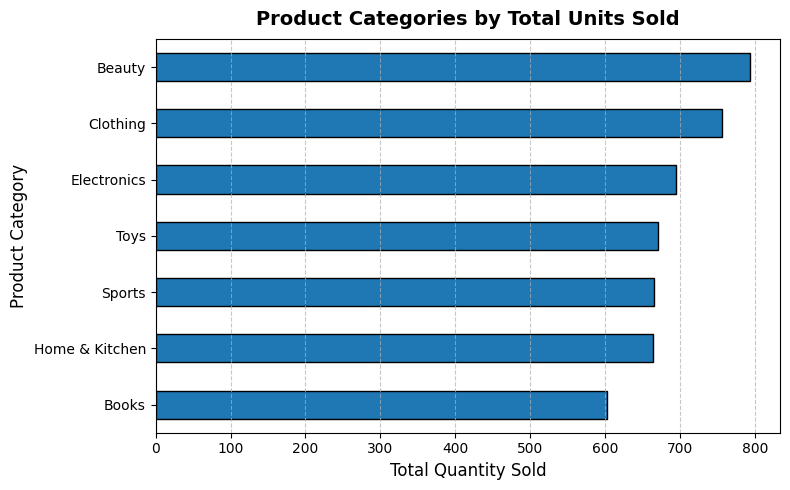

In [ ]:
# Horizontal bar chart: Product category with the most sales volume

(df.groupby('Category')['Quantity'].sum()
 .sort_values()
 .plot(kind='barh',
       color='#1f77b4',
       edgecolor='black',
       figsize=(8,5)))

plt.title('Product Categories by Total Units Sold', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('Total Quantity Sold', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

Beauty has the highest sales volume, followed by Clothing. Books has the lowest sales volume among all categories.

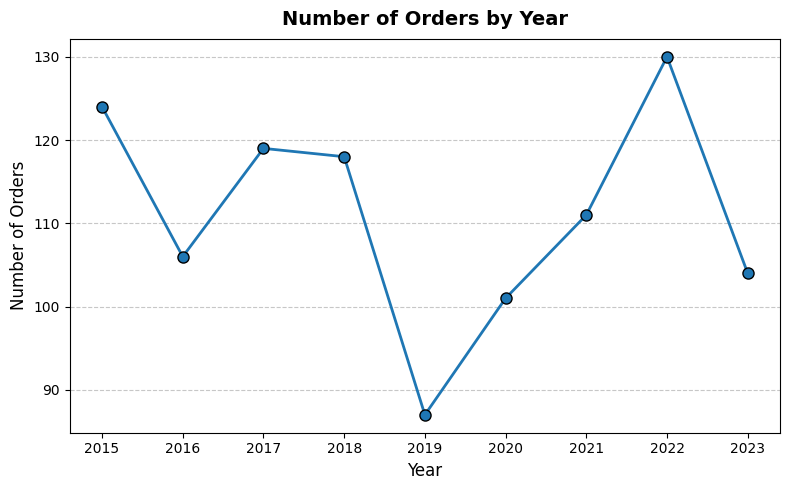

In [ ]:
# Line chart: Year with the most number of orders

df['Year'] = pd.to_datetime(df['OrderDate']).dt.year

orders_per_year = df['Year'].value_counts().sort_index()

plt.figure(figsize=(8,5))
plt.plot(orders_per_year.index, orders_per_year.values,
         marker='o', markersize=8, markeredgecolor='black',
         markerfacecolor='#1f77b4', linewidth=2)

plt.title('Number of Orders by Year', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

The highest number of orders was in 2022, followed by a drop in 2019, and in 2023, the number of orders decreased, showing a decline after the peak in 2022, while the numbers rose steadily from 2019 to 2022.

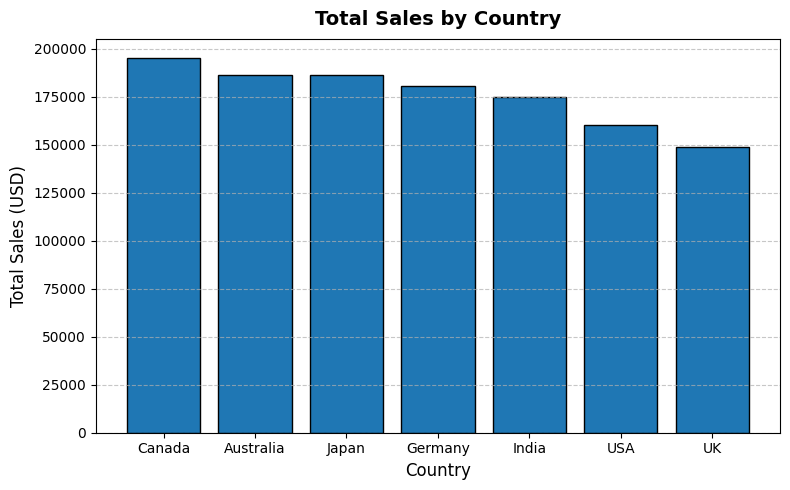

In [ ]:
# Bar chart: Country with the highest total sales

sales_by_country = df.groupby('Country')['TotalSales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
plt.bar(sales_by_country.index, sales_by_country.values,
        color='#1f77b4', edgecolor='black')

plt.title('Total Sales by Country', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Total Sales (USD)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Canada has the highest total sales, whereas the United Kingdom has the lowest.

##**Task 4: Plot Evaluation and Improvement**

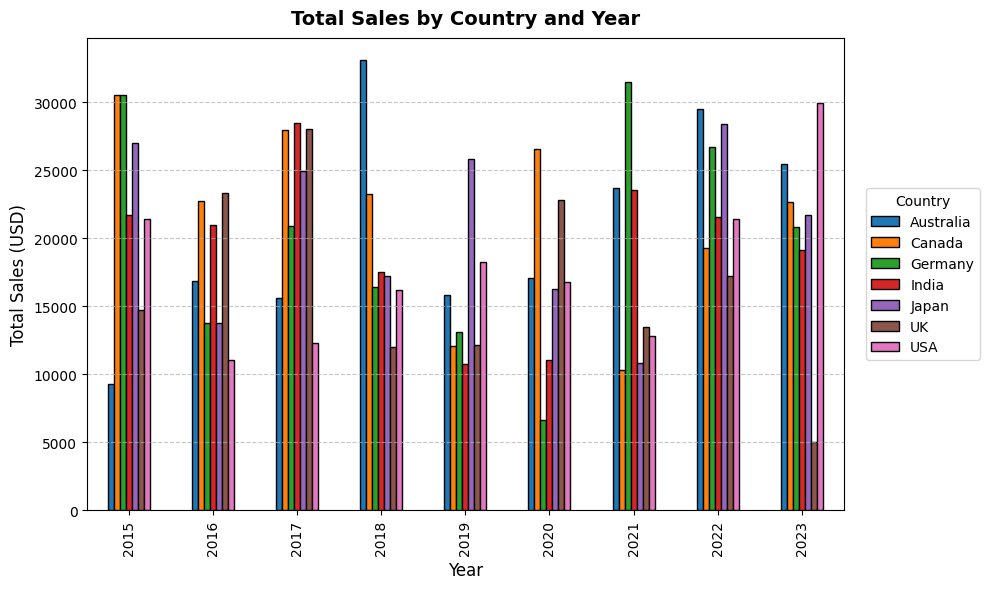

In [ ]:
# Grouped Bar Chart: Total Sales by Country and Year

df['Year'] = pd.to_datetime(df['OrderDate']).dt.year
sales_trend = df.groupby(['Year', 'Country'])['TotalSales'].sum().unstack()

sales_trend.plot(kind='bar', figsize=(10,6), edgecolor='black')

plt.title('Total Sales by Country and Year', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Sales (USD)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Country', bbox_to_anchor=(1.02, 0.5), loc='center left')

plt.tight_layout()
plt.show()

The original bar chart showed total sales by country for the entire period. Canada had the highest. It was useful for comparing countries overall, but didn’t show changes over the years. This new chart shows how sales changed year by year.

##**Task 5: Sales Trend Analysis**

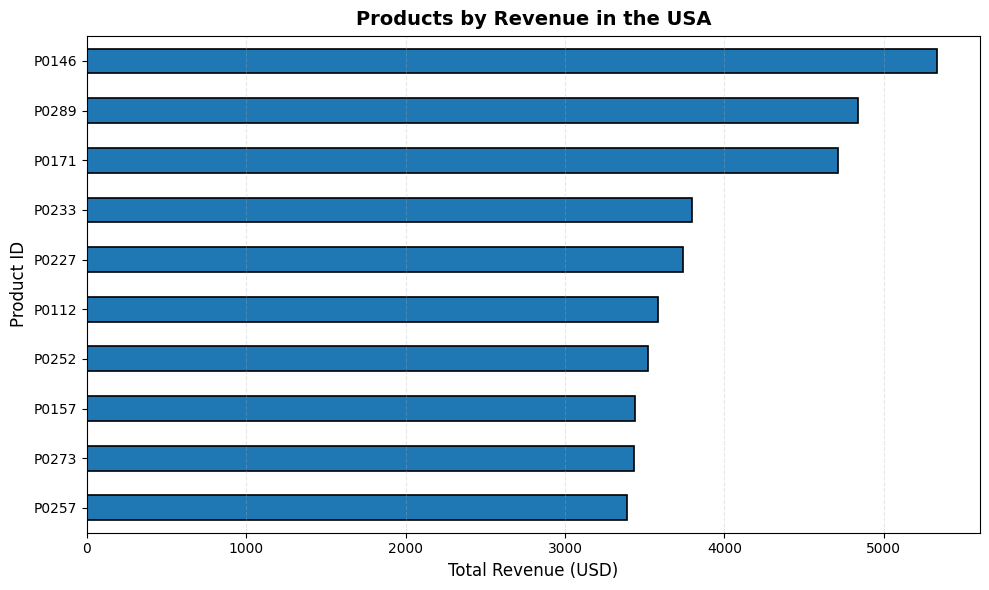

In [ ]:
# Best-selling product in terms of revenue in the USA

usa_sales = df[df['Country'] == 'USA']

top_products = usa_sales.groupby('ProductID')['TotalSales'].sum().nlargest(10).sort_values()

top_products.plot(
    kind='barh',
    color='#1f77b4',
    edgecolor='black',
    linewidth=1.2,
    figsize=(10, 6))


plt.title('Products by Revenue in the USA', fontsize=14, fontweight='bold', pad=8)
plt.xlabel('Total Revenue (USD)', fontsize=12)
plt.ylabel('Product ID', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Product P0146 generated the highest total revenue in the USA.

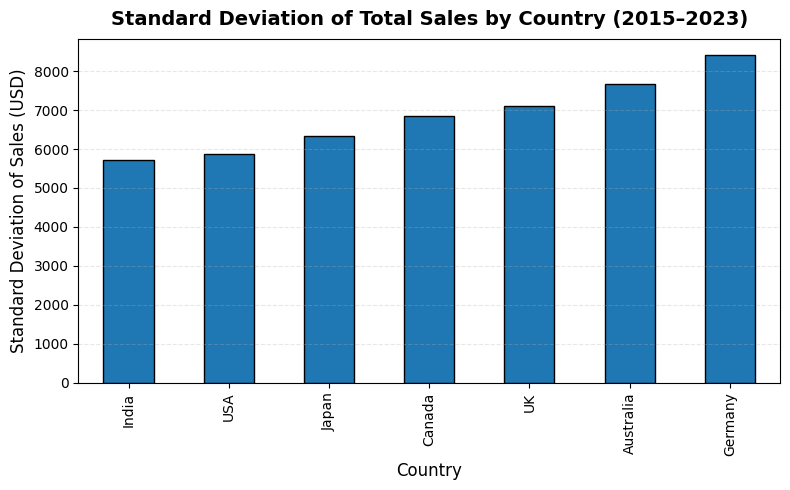

In [ ]:
# Country with consistent sales over the years (2015–2023)

df['Year'] = pd.to_datetime(df['OrderDate']).dt.year

country_year_sales = df.groupby(['Year', 'Country'])['TotalSales'].sum().unstack()

sales_std = country_year_sales.std().sort_values()

sales_std.plot(
    kind='bar',
    color='#1f77b4',
    edgecolor='black',
    figsize=(8, 5))

plt.title('Standard Deviation of Total Sales by Country (2015–2023)', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Standard Deviation of Sales (USD)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

India had the most consistent sales from 2015–2023, with the smallest changes in sales from year to year compared to other countries.

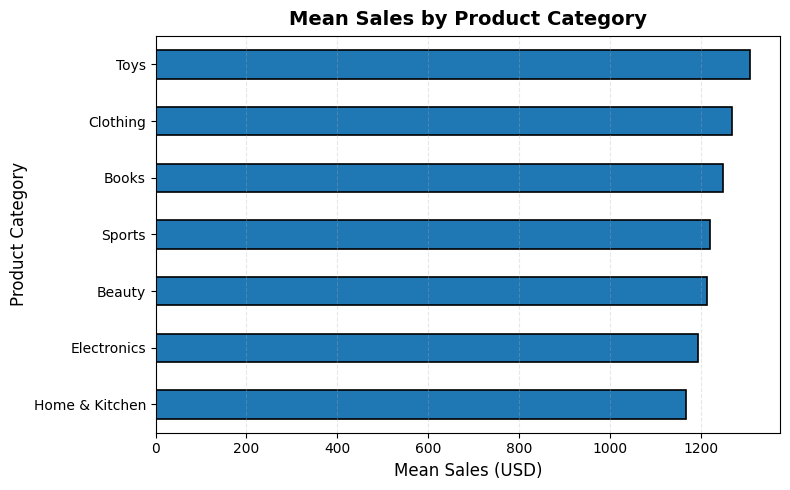

In [ ]:
# Mean sales by product category

category_average = df.groupby('Category')['TotalSales'].mean().sort_values()

category_average.plot(
    kind='barh',
    color='#1f77b4',
    edgecolor='black',
    linewidth=1.2,
    figsize=(8, 5))

plt.title('Mean Sales by Product Category', fontsize=14, fontweight='bold', pad=8)
plt.xlabel('Mean Sales (USD)', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

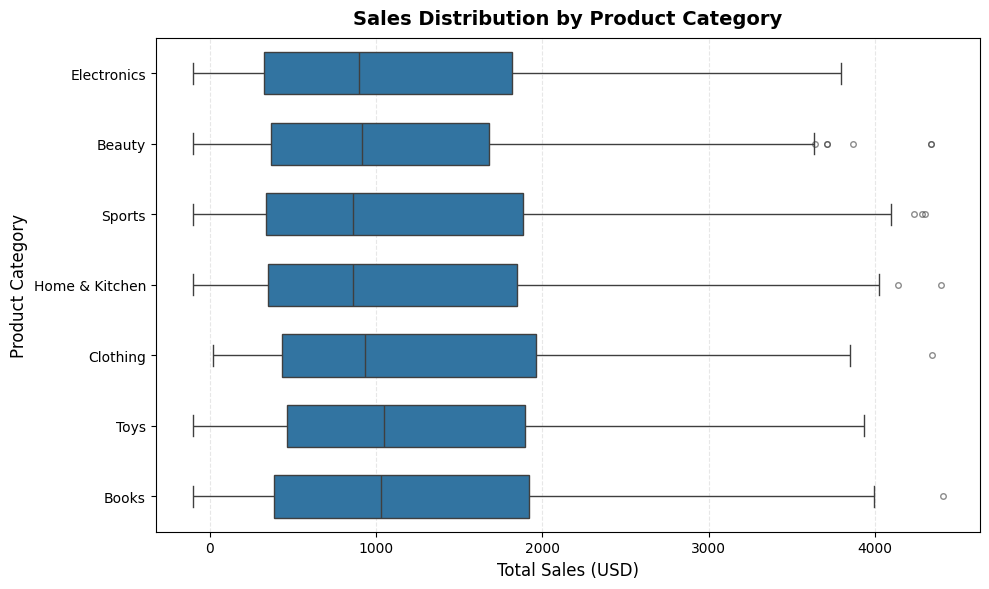

In [ ]:
# Sales distribution by product category

import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x='TotalSales',
    y='Category',
    color='#1f77b4',
    width=0.6,
    flierprops=dict(marker='o', markersize=4, alpha=0.6))

plt.title("Sales Distribution by Product Category", fontsize=14, fontweight='bold', pad=10)
plt.xlabel("Total Sales (USD)", fontsize=12)
plt.ylabel("Product Category", fontsize=12)
plt.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

Toys has the highest average sales, whereas Sports shows the greatest variability, indicating a broader range of sales values across different years.